# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

#### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

#### After the sentences have been assigned to their clusters, we can extract the candidate topics for each cluster using tokens of it's sentences

### 1. Reading and preprocessing the data

In [1]:
from utilities.document_preprocessing import preprocess_documents

#### The preprocess_document function reads the sentences from the file and generates tokens from each sentences.

In [2]:
# Input file
file = "data/PMP_Skills_Matching_Pilot_2018_2019_small.xlsx"

In [3]:
Verbose = True

In [4]:
sentences, token_lists = preprocess_documents(file, verbose = Verbose)

Reading the file
Preprocessing raw texts 



leadership strategy support key projects initiatives
Candidate Tokens:  ['leadership', 'strategy', 'support', 'projects', 'initiatives']


support inspirational leadership initiatives identified throughout the year
Candidate Tokens:  ['support', 'leadership', 'initiatives', 'year']


establish continue rapport strengthen relationship with any coe supporting initiatives for your respective areas
Candidate Tokens:  ['continue', 'rapport', 'strengthen', 'relationship', 'coe', 'initiatives', 'areas']


support employee central when it is introduced and rolled out
Candidate Tokens:  ['support', 'employee']


support drive efforts to deliver inclusion traing
Candidate Tokens:  ['support', 'drive', 'efforts', 'inclusion']


leadership strategy support key projects initiatives
Candidate Tokens:  ['leadership', 'strategy', 'support', 'projects', 'initiatives']


support inspirational leadership initiatives identified throughout the year
Candidate Tok



talent refresh biologics key talent list and succession planning to l5
Candidate Tokens:  ['talent', 'refresh', 'biologics', 'list', 'succession', 'planning']


support kpis and visibility to advancing women in leadership support diversity and inclusion
Candidate Tokens:  ['support', 'kpis', 'visibility', 'women', 'leadership', 'support', 'diversity', 'inclusion']


if appropriate within your area continue to progress biologics talent development initiative focused on site leaders
Candidate Tokens:  ['area', 'continue', 'biologics', 'development', 'initiative', 'site', 'leaders']


support leadership programs when appropriate
Candidate Tokens:  ['support', 'leadership', 'programs', 'appropriate']


hold drive your development sessions with managers and employees
Candidate Tokens:  ['development', 'sessions', 'managers', 'employees']


create define communicate a path for growth for lab techs and animal techs for ramona
Candidate Tokens:  ['create', 'define', 'path', 'growth', 'lab', 



the biologics hrbp s will present out highlights of their employee engagement action plan on a dedicated telecon among other biologic hrbps an informational exchange session
Candidate Tokens:  ['biologics', 's', 'highlights', 'employee', 'engagement', 'action', 'plan', 'telecon', 'exchange', 'session']


targeting 3rd quarter
Candidate Tokens:  ['quarter']


ensure all biologics employees have at least 1 development objective executed by year end 2019
Candidate Tokens:  ['biologics', 'employees', 'development', 'objective', 'year', 'end']


100 of employees are expected to have an development objective in the system by no later than end of may 2019
Candidate Tokens:  ['employees', 'development', 'objective', 'system', 'end']


snap shot of active employees taken as of may 1 2019
Candidate Tokens:  ['shot', 'employees']


evaluate needs and drive efforts among the biologics cluster to conduct lunch n learns facilitate train when appropriate
Candidate Tokens:  ['evaluate', 'needs', 'dr



deliver the ta function change programme 1 ensure team personal increase in the value of direct sourcing of 5 target saving 2019 is of 330 000 for a full year presence and with same reqs volume as in 2018
Candidate Tokens:  ['ta', 'function', 'change', 'programme', 'team', 'increase', 'value', 'sourcing', 'target', 'saving', 'year', 'presence', 'reqs', 'volume']


2 country region business based ta strategy developed and implemented based on business priority focus 3 fully implement technology roll outs 4 lead participate in specific global regional and or local ta projects including hogan assessment roll out data driven hiring vie
Candidate Tokens:  ['country', 'region', 'business', 'ta', 'strategy', 'business', 'priority', 'focus', 'technology', 'roll', 'outs', 'participate', 'ta', 'projects', 'assessment', 'roll', 'data', 'vie']


deliver the ta function change programme 1 ensure team personal increase in the value of direct sourcing of 5 target saving 2019 is of 330 000 for a ful



support the roll out of global projects including new technology candidate experience and d i initiatives been collaborative within the team providing assistance to colleagues where need
Candidate Tokens:  ['support', 'roll', 'projects', 'technology', 'candidate', 'experience', 'd', 'initiatives', 'team', 'assistance', 'colleagues', 'need']


contribution to the talent acquisition strategy evidence will be sought to show that each team member has been proactive in identifying opportunities for improvement in their own area and across the function understood the strategy shared it and publicized successes with their teams peers and stakeholders
Candidate Tokens:  ['contribution', 'talent', 'acquisition', 'strategy', 'evidence', 'team', 'member', 'opportunities', 'improvement', 'area', 'function', 'strategy', 'successes', 'teams', 'peers', 'stakeholders']


support the roll out of global projects including new technology candidate experience and d i initiatives been collaborative withi



employee central project to be delivered with defined scope on time and in budget timely completion of milestones as per the defined project roadmap
Candidate Tokens:  ['employee', 'project', 'scope', 'time', 'budget', 'completion', 'milestones', 'project', 'roadmap']


employee central project to be delivered with defined scope on time and in budget all milestones in collaboration with other ec workstreams in alignment and on time as per roadmap
Candidate Tokens:  ['employee', 'project', 'scope', 'time', 'budget', 'milestones', 'collaboration', 'workstreams', 'alignment', 'time', 'roadmap']


enablement approach drafted and shared along with rfp
Candidate Tokens:  ['approach', 'rfp']


development of material and actual delivery will be scheduled in q1 q2 20 business communication draft with key messages now be aligned with overall hr strategy change communication deck
Candidate Tokens:  ['development', 'material', 'delivery', 'business', 'communication', 'draft', 'messages', 'hr', 

### 2. Topic Modeling

In [5]:
from models.topic_model import Topic_Model

#### The topic_Model class does the follow
- Extract Bert sentence embeddings for all sentences (Local features)
- get topic distribution for each sentence using LDA
- concatenate both and learn the latent representation using an auto-encoder
- cluster the latent representation into K clusters

In [6]:
# Define the topic model object
TopicModelObject = Topic_Model(k = 2 , embedding = 'xlnet',  verbose = Verbose)

In [7]:
# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

Getting vector representations for LDA 
Dictionary used for LDA 

0 initiatives
1 leadership
2 projects
3 strategy
4 support
5 year
6 areas
7 coe
8 continue
9 rapport
10 relationship
11 strengthen
12 employee
13 drive
14 efforts
15 inclusion
16 kathy
17 business
18 leaders
19 partner
20 partnership
21 analysis
22 learnings
23 learns
24 lunch
25 n
26 optimization
27 skills
28 traings
29 contributions
30 thank
31 caprice
32 november
33 fact
34 ideas
35 judgements
36 thoughts
37 value
38 buy
39 decision
40 making
41 obtaing
42 team
43 abilities
44 compensation
45 relationships
46 s
47 strides
48 forum
49 opportunities
50 women
51 changes
52 growth
53 level
54 org
55 organization
56 path
57 planning
58 production
59 re
60 role
61 structure
62 bias
63 development
64 employees
65 feedback
66 learning
67 plans
68 biologics
69 list
70 refresh
71 succession
72 talent
73 diversity
74 kpis
75 visibility
76 area
77 initiative
78 site
79 appropriate
80 programs
81 managers
82 sessions
83 animal
84 


 
 Shape of LDA Vector:  (302, 2)
[[0.90749967 0.09250034]
 [0.89257306 0.10742702]
 [0.93471068 0.06528929]
 [0.81414157 0.18585838]
 [0.88100106 0.11899891]
 [0.90750474 0.0924952 ]
 [0.89257956 0.10742044]
 [0.93470132 0.06529868]
 [0.81412971 0.18587025]
 [0.88099557 0.11900442]
 [0.90751088 0.09248907]
 [0.89257926 0.10742078]
 [0.93471116 0.06528883]
 [0.81413609 0.18586387]
 [0.88100809 0.11899193]
 [0.90750873 0.09249126]
 [0.89256912 0.10743088]
 [0.93470198 0.06529804]
 [0.8141433  0.18585667]
 [0.88103604 0.11896401]
 [0.59168386 0.4083162 ]
 [0.14817861 0.85182142]
 [0.14708582 0.85291415]
 [0.17020343 0.82979655]
 [0.83151978 0.1684802 ]
 [0.86102635 0.13897367]
 [0.89256525 0.10743477]
 [0.9347111  0.06528888]
 [0.8141619  0.18583807]
 [0.88098121 0.11901885]
 [0.29496261 0.70503742]
 [0.89530569 0.10469434]
 [0.40849259 0.59150743]
 [0.11923397 0.88076603]
 [0.25278443 0.74721551]
 [0.33671051 0.66328949]
 [0.91256791 0.08743206]
 [0.20077844 0.79922158]
 [0.78338957 0.

Epoch 1 of 10, Train Loss: 68.821
Epoch 2 of 10, Train Loss: 68.748
Epoch 3 of 10, Train Loss: 68.672
Epoch 4 of 10, Train Loss: 68.650
Epoch 5 of 10, Train Loss: 68.649
Epoch 6 of 10, Train Loss: 68.634
Epoch 7 of 10, Train Loss: 68.660
Epoch 8 of 10, Train Loss: 68.630
Epoch 9 of 10, Train Loss: 68.672
Epoch 10 of 10, Train Loss: 68.601
Fitting Autoencoder Done!
Latent Representation size:  (302, 32)
Clustering the latent representations
Clustering. Done!


In [8]:
labels = set(TopicModelObject.cluster_model.labels_)
for label in labels:
    index = []
    for idx, l in enumerate(TopicModelObject.cluster_model.labels_):
        if l == label:
            index.append(idx)
    print ('\n \nSentences belong to cluster ', str (label+1), ' are: \n ')
    for i in index:
        print (sentences[i])


 
Sentences belong to cluster  1  are: 
 
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
establish continue rapport strengthen relationship with any coe supporting initiatives for your respective areas
support employee central when it is introduced and rolled out
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
establish continue rapport strengthen relationship with any coe supporting initiatives for your respective areas
support employee central when it is introduced and rolled out
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
establish continue rapport strengthen relationship with any coe supporting initiatives for your respective areas
support employee central when it is introduced and rolled out
leadership strategy support key projects init

In [9]:
# To get the top words for each topic, this method only uses LDA, doesn't utilize embeddings or K mean clustering
TopicModelObject.get_top_words_lda(top=6)

{0: [('support', 0.04390477),
  ('initiatives', 0.023780786),
  ('team', 0.020789456),
  ('development', 0.01948263),
  ('employees', 0.018782996),
  ('year', 0.018487578)],
 1: [('biologics', 0.03125799),
  ('business', 0.026126267),
  ('feedback', 0.022022238),
  ('candidates', 0.014444011),
  ('process', 0.014153701),
  ('headcount', 0.013618946)]}

## Visualizations

In [10]:
from utilities.visualizations import *
%matplotlib inline

/home/anum/anaconda3/envs/nlp/lib/python3.8/site-packages/umap/spectral.py:4: NumbaDeprecationWarning: No direct replacement for 'numba.targets' available. Visit https://gitter.im/numba/numba-dev to request help. Thanks!
  import numba.targets


Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!


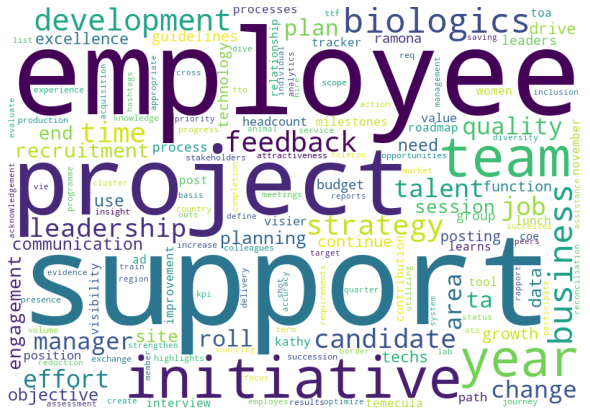

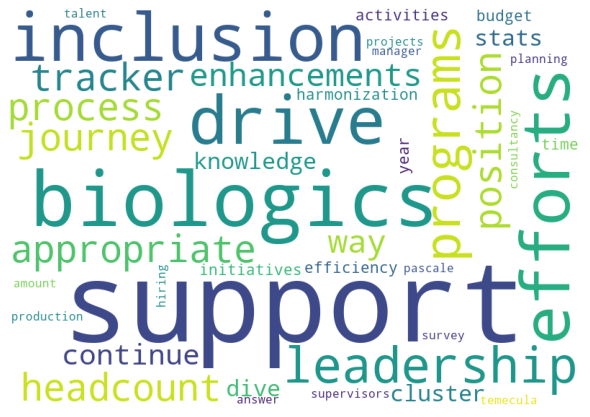

In [11]:
# visualize and save img
#visualize(TopicModelObject)
for i in range(TopicModelObject.k):
    get_wordcloud(TopicModelObject, token_lists, i)